In [2]:
# # -----------------------
# # Nbits comparison plots (avg_tokens=0 and 1, n_tokens=20)
# # -----------------------
# n_tokens_cmp = 20
# avg_tokens_cmp_list = [0, 1]

# for language_pair_id, (languageA, languageB) in enumerate(language_pairs):
#     layers = get_layers(model, depths)
#     x = layers / depths[model]

#     for avg_tokens_cmp in avg_tokens_cmp_list:
#         mean_ii_0, _ = load_ii_curves(
#             base="./results/santiago/",
#             batch_shuffle=batch_shuffle,
#             model=model,
#             aux_A=aux_A,
#             aux_B=aux_B,
#             n_files=n_files,
#             min_token_length=min_token_length,
#             languageA=languageA,
#             languageB=languageB,
#             mask=mask,
#             k=k_II,
#             Nbits=0,
#             seeds=[0],
#             n_tokens=n_tokens_cmp,
#             avg_tokens=avg_tokens_cmp,
#         )

#         mean_ii_1, _ = load_ii_curves(
#             base="./results/santiago/",
#             batch_shuffle=batch_shuffle,
#             model=model,
#             aux_A=aux_A,
#             aux_B=aux_B,
#             n_files=n_files,
#             min_token_length=min_token_length,
#             languageA=languageA,
#             languageB=languageB,
#             mask=mask,
#             k=k_II,
#             Nbits=1,
#             seeds=seeds_II,
#             n_tokens=n_tokens_cmp,
#             avg_tokens=avg_tokens_cmp,
#         )

#         fig, ax = plt.subplots(1, 1, figsize=(6, 4))
#         # AB direction: plot Nbits=0 and Nbits=1 superimposed
#         ax.plot(x, mean_ii_0[0], label="Nbits=0", linestyle='-', color=colors[0], marker='o')
#         ax.plot(x, mean_ii_1[0], label="Nbits=1", linestyle='--', color=colors[0], marker='s')

#         ax.set_xlabel("relative depth")
#         ax.set_ylabel("Information Imbalance")
#         ax.set_title(f"{languageA.capitalize()} → {languageB.capitalize()} | T={n_tokens_cmp} | avg={avg_tokens_cmp}")
#         ax.legend()
#         plt.show()


In [3]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()


/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


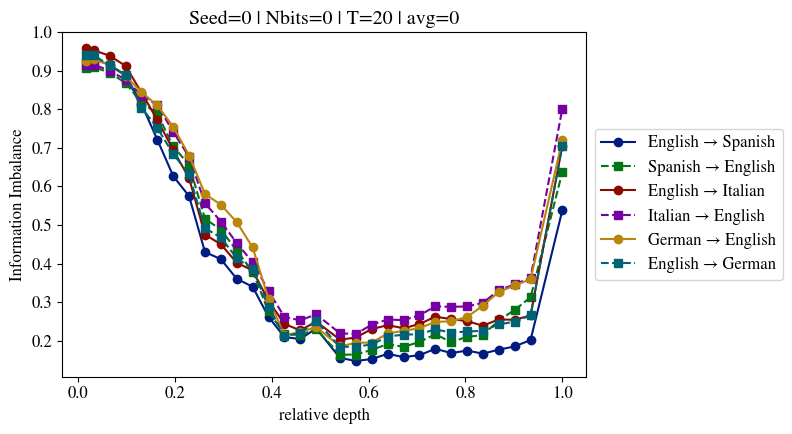

In [6]:
model = "deepseek"
MODEL_PRETTY = {"deepseek": "DeepSeek-V3", "llama": "L3"}
_model = MODEL_PRETTY.get(model, model)

mask = 2
n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0

# -----------------------
# Seed-0 II curves (avg_tokens=0, Nbits=0, n_tokens=20)
# English-Spanish, English-Italian, English-German (AB and BA)
# -----------------------
aux_A = "source"
aux_B = "target"
k_II = 10
min_token_length = 40
avg_tokens_cmp = 0
n_tokens_cmp = 20
Nbits_cmp = 0
seeds_cmp = [0]
language_pairs_cmp = [
    ("english", "spanish"),
    ("english", "italian"),
    ("german","english"),
]

layers = get_layers(model, depths)
x = layers / depths[model]

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))

for i, (languageA, languageB) in enumerate(language_pairs_cmp):
    mean_ii, _ = load_ii_curves(
        base="../results/santiago/",
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=min_token_length,
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits_cmp,
        seeds=seeds_cmp,
        n_tokens=n_tokens_cmp,
        avg_tokens=avg_tokens_cmp,
    )

    color_AB = colors[(2 * i) % len(colors)]
    color_BA = colors[(2 * i + 1) % len(colors)]

    # AB
    ax.plot(
        x,
        mean_ii[0],
        label=f"{languageA.capitalize()} → {languageB.capitalize()}",
        linestyle='-',
        marker='o',
        color=color_AB,
    )

    # BA
    ax.plot(
        x,
        mean_ii[1],
        label=f"{languageB.capitalize()} → {languageA.capitalize()}",
        linestyle='--',
        marker='s',
        color=color_BA,
    )

ax.set_xlabel("relative depth")
ax.set_ylabel("Information Imbalance")
ax.set_title("Seed=0 | Nbits=0 | T=20 | avg=0")

# Legend outside
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()


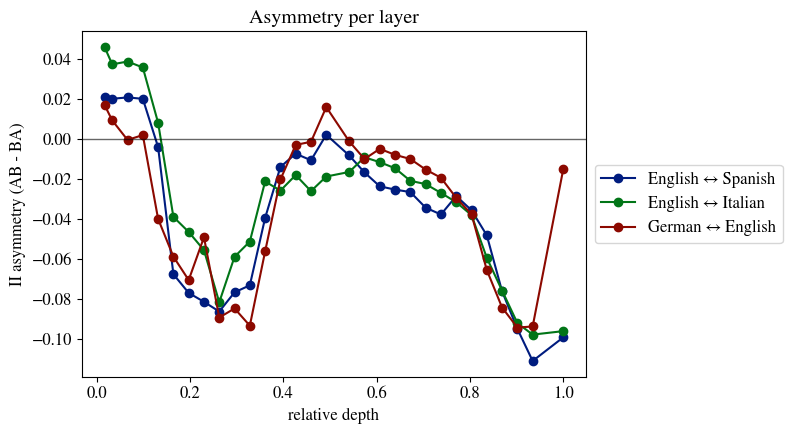

In [8]:
# -----------------------
# Asymmetry per layer (AB - BA), all language pairs on one plot
# Uses current config from the notebook
# -----------------------
fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))

layers = get_layers(model, depths)
x = layers / depths[model]

for language_pair_id, (languageA, languageB) in enumerate(language_pairs_cmp):
    mean_ii, _ = load_ii_curves(
        base="../results/santiago/",
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=min_token_length,
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits_cmp,
        seeds=seeds_cmp,
        n_tokens=n_tokens_cmp,
        avg_tokens=avg_tokens_cmp,
    )

    asym = mean_ii[0] - mean_ii[1]
    asym = -1 * asym if languageA == "german" else asym  # Invert German-English
    color = colors[language_pair_id % len(colors)]
    ax.plot(
        x,
        asym,
        label=f"{languageA.capitalize()} ↔ {languageB.capitalize()}",
        color=color,
        marker='o',
    )

ax.axhline(0, color='black', linewidth=1, alpha=0.6)
ax.set_xlabel("relative depth")
ax.set_ylabel("II asymmetry (AB - BA)")
ax.set_title("Asymmetry per layer")

box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()


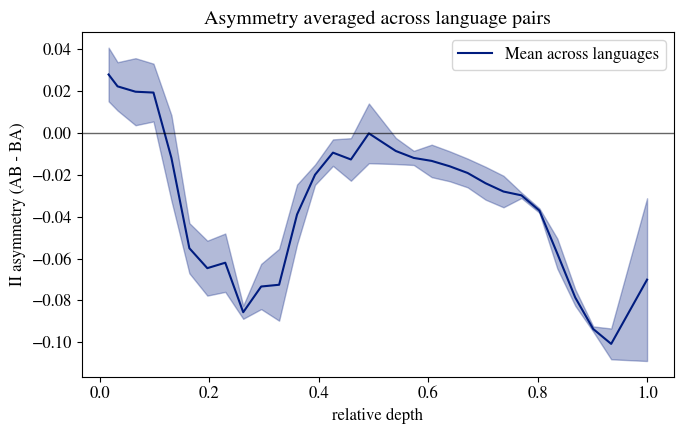

In [12]:
# -----------------------
# Average asymmetry across language pairs with 1 std band
# -----------------------
layers = get_layers(model, depths)
x = layers / depths[model]

asym_list = []
for (languageA, languageB) in language_pairs_cmp:
    mean_ii, _ = load_ii_curves(
        base="../results/santiago/",
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=min_token_length,
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits_cmp,
        seeds=seeds_cmp,
        n_tokens=n_tokens_cmp,
        avg_tokens=avg_tokens_cmp,
    )
    a = mean_ii[0] - mean_ii[1]
    a = -1 * a if languageA == "german" else a  #
    asym_list.append(a)

asym = np.stack(asym_list, axis=0)
asym_mean = asym.mean(axis=0)
asym_std = asym.std(axis=0)

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))
ax.plot(x, asym_mean, color=colors[0], label="Mean across languages")
ax.fill_between(x, asym_mean - asym_std, asym_mean + asym_std, color=colors[0], alpha=0.3)

ax.axhline(0, color='black', linewidth=1, alpha=0.6)
ax.set_xlabel("relative depth")
ax.set_ylabel("II asymmetry (AB - BA)")
ax.set_title("Asymmetry averaged across language pairs")
ax.legend()
fig.savefig(fname=f'../results/figs/fig1_asym_avg_languages.pdf', bbox_inches='tight')
plt.show()
